In [71]:
## import required/relevant libraries
import os, json, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

In [72]:
## inputs directory 
data_directory = '/kaggle/input/competitions/cassava-leaf-disease-classification'
image_directory = os.path.join(data_directory, 'train_images')
train_csv = os.path.join(data_directory, "train.csv") 
label_map_json = os.path.join(data_directory, "label_num_to_disease_map.json")

In [73]:
## check dataset folders attached
print("Input folders:", os.listdir("/kaggle/input"))

Input folders: ['competitions']


In [74]:
##load labels
train_df = pd.read_csv(train_csv)

with open (label_map_json, 'r') as f:
    label_map = {int(k): v for k, v in json.load(f).items()}

train_df["label"] = train_df["label"].astype(int)
train_df["filepath"] = train_df["image_id"].apply(
    lambda image_id: os.path.join(image_directory, image_id)
)

In [75]:
#count images in each class
class_counts = (
    train_df["label"]
    .value_counts()
    .reindex(sorted(label_map), fill_value=0)
)

counts_df = pd.DataFrame({
    "label_id": class_counts.index,
    "class_name": [label_map[i] for i in class_counts.index],
    "image_count": class_counts.values,
})

display(counts_df)

,label_id,class_name,image_count
0,0,Cassava Bacterial Blight (CBB),1087
1,1,Cassava Brown Streak Disease (CBSD),2189
2,2,Cassava Green Mottle (CGM),2386
3,3,Cassava Mosaic Disease (CMD),13158
4,4,Healthy,2577


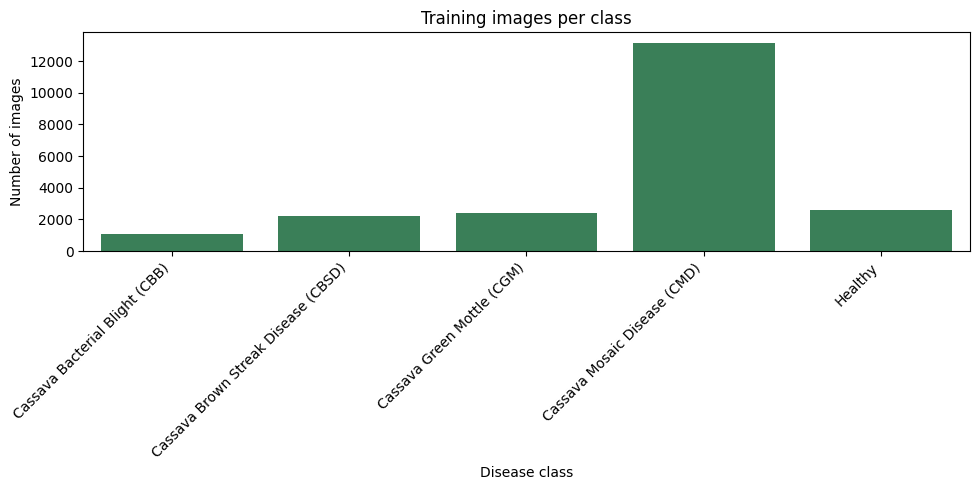

In [76]:
##plot class_counts to see imbalance
plt.figure(figsize=(10, 5))
sns.barplot(
    counts_df,
    x="class_name",
    y="image_count",
    color="seagreen"
)
plt.title("Training images per class")
plt.xlabel("Disease class")
plt.ylabel("Number of images")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [77]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

In [78]:
##split labeled images into training and validation sets
train_data, val_data = train_test_split(
    train_df,
    test_size=0.2,
    random_state=SEED,
    stratify=train_df["label"],
)

train_data = train_data.reset_index(drop=True)
val_data = val_data.reset_index(drop=True)

print(f"Training images {len(train_data)}")
print(f"Validation images {len(val_data)}")

Training images 17117
Validation images 4280


In [79]:
##compare class counts in each split
split_counts = pd.DataFrame({
    "train": train_data["label"].value_counts().reindex(sorted(label_map), fill_value=0),
    "validation": val_data["label"].value_counts().reindex(sorted(label_map), fill_value=0)
})
split_counts.index = [label_map[i] for i in split_counts.index]
display(split_counts)

,train,validation
Cassava Bacterial Blight (CBB),870,217
Cassava Brown Streak Disease (CBSD),1751,438
Cassava Green Mottle (CGM),1909,477
Cassava Mosaic Disease (CMD),10526,2632
Healthy,2061,516


In [80]:
##calculate a larger weight for classes with fewer training images
classes = np.array(sorted(train_data["label"].unique()))

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=train_data["label"].to_numpy()
)

class_weights = {
    int(class_id): float(weight)
    for class_id, weight in zip(classes, weights)
}

weight_table = pd.DataFrame({
    "label_id": classes,
    "class_name": [label_map[int(class_id)] for class_id in classes],
    "class_weight": weights
})
display(weight_table)

,label_id,class_name,class_weight
0,0,Cassava Bacterial Blight (CBB),3.934943
1,1,Cassava Brown Streak Disease (CBSD),1.955111
2,2,Cassava Green Mottle (CGM),1.793295
3,3,Cassava Mosaic Disease (CMD),0.325233
4,4,Healthy,1.661038


In [81]:
IMG_SIZE = (224, 224)

def load_and_resize_image(filepath, label):
    image_bytes = tf.io.read_file(filepath)
    image = tf.io.decode_jpeg(image_bytes, channels=3)
    image = tf.image.resize(image, IMG_SIZE)
    label = tf.cast(label, tf.int32)
    return image, label

train_paths = train_data["filepath"].to_numpy(dtype=str)
train_labels = train_data["label"].to_numpy(dtype=np.int32)

weight_vector = np.array(
    [class_weights[i] for i in range(len(label_map))],
    dtype=np.float32
)
weight_tensor = tf.constant(weight_vector)


In [82]:
##test image loader
probe_ds = tf.data.Dataset.from_tensor_slices(
    (train_paths[:2], train_labels[:2])
)
probe_ds = probe_ds.map(load_and_resize_image)
print("After loading image:", probe_ds.element_spec)

After loading image: (TensorSpec(shape=(224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(), dtype=tf.int32, name=None))


In [83]:
##test adding class weights
probe_ds = probe_ds.map(
    lambda image, label: (
        image,
        label,
        tf.gather(weight_tensor, label),
    )
)
print("After adding weights:", probe_ds.element_spec)

After adding weights: (TensorSpec(shape=(224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(), dtype=tf.int32, name=None), TensorSpec(shape=(), dtype=tf.float32, name=None))


In [84]:
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

##validation paths and labels
val_paths = val_data["filepath"].to_numpy(dtype=str)
val_labels = val_data["label"].to_numpy(dtype=np.int32)

In [85]:
##training dataset; shuffle, load images, add class weights and batch
train_ds = tf.data.Dataset.from_tensor_slices((train_paths, train_labels))
train_ds = train_ds.shuffle(
    buffer_size=len(train_paths),
    seed=SEED,
    reshuffle_each_iteration=True
)
train_ds = train_ds.map(
    load_and_resize_image,
    num_parallel_calls=AUTOTUNE
)
train_ds = train_ds.map(
    lambda image, label: (
        image,
        label,
        tf.gather(weight_tensor, label)
    ),
    num_parallel_calls=AUTOTUNE
)
train_ds = train_ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)

In [86]:
##validation dataset: doesn't need shuffling or class weights
val_ds = tf.data.Dataset.from_tensor_slices((val_paths, val_labels))
val_ds = val_ds.map(
    load_and_resize_image,
    num_parallel_calls=AUTOTUNE
)
val_ds = val_ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)

Images: (32, 224, 224, 3)
Labels: (32,)
Weights: (32,)


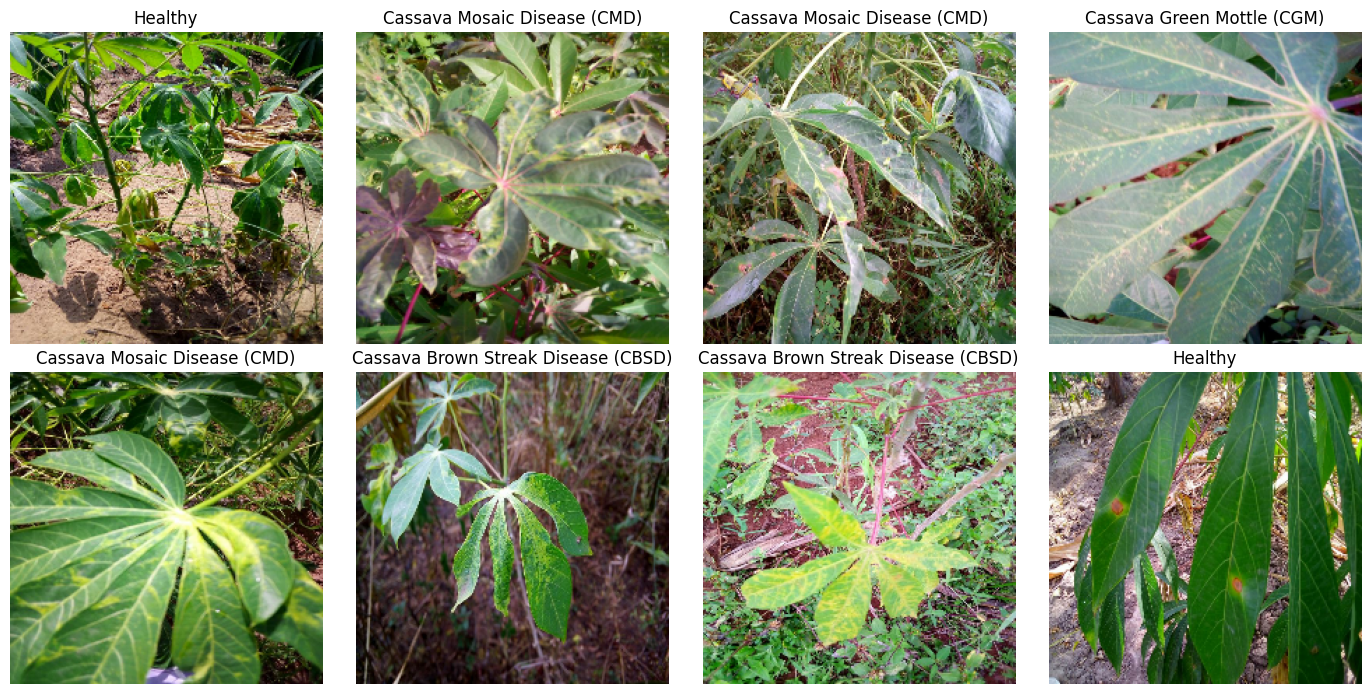

In [87]:
##check the batch dimensions and preview a few training images
images, labels, sample_weights = next(iter(train_ds))

print("Images:", images.shape)
print("Labels:", labels.shape)
print("Weights:", sample_weights.shape)

fig, axes = plt.subplots(
    2,
    4,
    figsize=(14, 7))

for ax, image, label in zip(axes.flat, images[:8], labels[:8]):
    ax.imshow(image.numpy().astype("uint8"))
    ax.set_title(label_map[int(label.numpy())])
    ax.axis("off")
plt.tight_layout()
plt.show()

In [88]:
##building a small cnn(Convolutional Neural Network )
num_classes = len(label_map)

###define the input layer
inputs = keras.Input(shape=(224, 224, 3))

###rescale pixels
x = layers.Rescaling(1.0 / 255)(inputs)

###three convolutional blocks via loop
for filters in [32, 64, 128]:
    x = layers.Conv2D(
        filters,
        kernel_size=3,
        padding="same",
        use_bias=False
    )(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.MaxPooling2D()(x)

###head of the network
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.4)(x)
outputs = layers.Dense(num_classes, activation="softmax")(x)

###build the model
baseline = keras.Model(inputs, outputs, name="small_cnn_baseline")

###compile the model
baseline.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"]
)

baseline.summary()

###setup callbacks
baseline_callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=2,
        restore_best_weights=True
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=1,
    )
]

baseline_history = baseline.fit(
    train_ds,
    validation_data=val_ds,
    epochs=8,
    callbacks=baseline_callbacks
)

Model: "small_cnn_baseline"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_7 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_7 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 224, 224, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 112, 112, 64)   │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 56, 56, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_5 (Activation)       │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_3      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 94,565 (369.39 KB)

 Trainable params: 94,117 (367.64 KB)

 Non-trainable params: 448 (1.75 KB)

Epoch 1/8
535/535 ━━━━━━━━━━━━━━━━━━━━ 66s 115ms/step - accuracy: 0.3520 - loss: 1.5598 - val_accuracy: 0.0607 - val_loss: 4.0578 - learning_rate: 0.0010
Epoch 2/8
535/535 ━━━━━━━━━━━━━━━━━━━━ 55s 102ms/step - accuracy: 0.4459 - loss: 1.4022 - val_accuracy: 0.0568 - val_loss: 3.5350 - learning_rate: 0.0010
Epoch 3/8
535/535 ━━━━━━━━━━━━━━━━━━━━ 56s 105ms/step - accuracy: 0.4961 - loss: 1.3201 - val_accuracy: 0.6175 - val_loss: 1.7028 - learning_rate: 0.0010
Epoch 4/8
535/535 ━━━━━━━━━━━━━━━━━━━━ 57s 107ms/step - accuracy: 0.5346 - loss: 1.2665 - val_accuracy: 0.5124 - val_loss: 1.1781 - learning_rate: 0.0010
Epoch 5/8
535/535 ━━━━━━━━━━━━━━━━━━━━ 48s 90ms/step - accuracy: 0.5513 - loss: 1.2263 - val_accuracy: 0.6000 - val_loss: 1.6511 - learning_rate: 0.0010
Epoch 6/8
535/535 ━━━━━━━━━━━━━━━━━━━━ 47s 87ms/step - accuracy: 0.5774 - loss: 1.1741 - val_accuracy: 0.4187 - val_loss: 1.5347 - learning_rate: 5.0000e-04


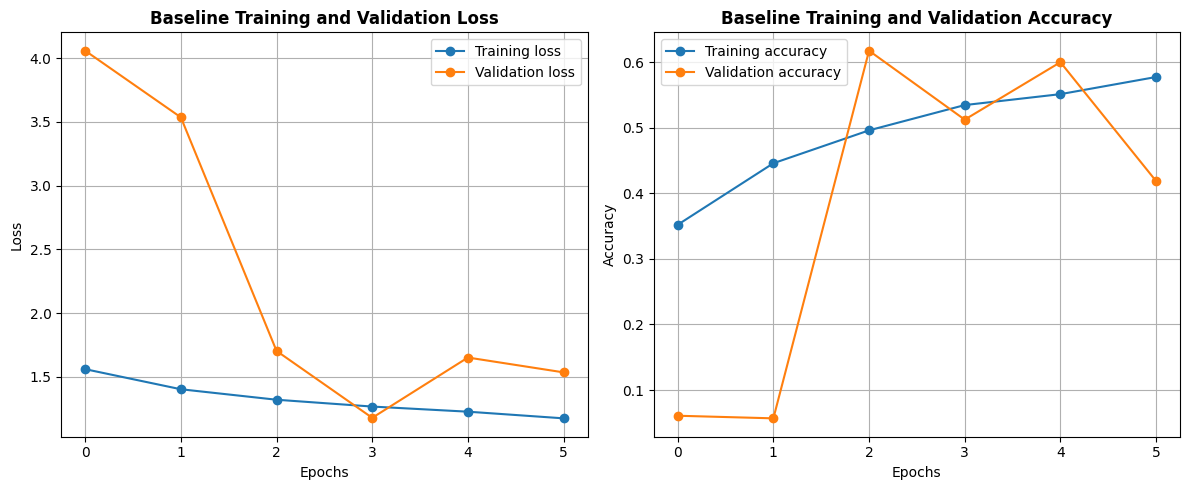

In [89]:
##extract history values
history_dict = baseline_history.history
loss = history_dict['loss']
val_loss = history_dict['val_loss']
accuracy = history_dict['accuracy']
val_accuracy = history_dict['val_accuracy']
epochs_range = range(len(loss))

##plotting
plt.figure(figsize=(12, 5))

###loss plot
plt.subplot(1, 2, 1)
plt.plot(
    epochs_range,
    loss,
    label="Training loss",
    marker="o"
)
plt.plot(
    epochs_range,
    val_loss,
    label="Validation loss",
    marker="o"
)
plt.title("Baseline Training and Validation Loss",
         fontsize=12,
         fontweight="bold"
)
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

###accuracy plot
plt.subplot(1, 2, 2)
plt.plot(
    epochs_range,
    accuracy,
    label="Training accuracy",
    marker="o"
)
plt.plot(
    epochs_range,
    val_accuracy,
    label="Validation accuracy",
    marker="o"
)
plt.title("Baseline Training and Validation Accuracy",
         fontsize=12,
         fontweight="bold"
)
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [90]:
##confusion matrix and classification report
###predictions on validation dataset
y_true_batches = []
y_pred_batches = []

for images, labels in val_ds:
    probabilities = baseline(images, training=False).numpy()
    y_true_batches.append(labels.numpy())
    y_pred_batches.append(np.argmax(probabilities, axis=1))

y_true = np.concatenate(y_true_batches)
y_pred = np.concatenate(y_pred_batches)

class_ids = sorted(label_map)
class_names = [label_map[i] for i in class_ids]

In [91]:
###print classification report
print(classification_report(
    y_true,
    y_pred,
    labels=class_ids,
    target_names=class_names,
    digits=3,
    zero_division=0
))

                                     precision    recall  f1-score   support

     Cassava Bacterial Blight (CBB)      0.303     0.230     0.262       217
Cassava Brown Streak Disease (CBSD)      0.186     0.728     0.296       438
         Cassava Green Mottle (CGM)      0.423     0.283     0.339       477
       Cassava Mosaic Disease (CMD)      0.890     0.586     0.707      2632
                            Healthy      0.426     0.283     0.340       516

                           accuracy                          0.512      4280
                          macro avg      0.445     0.422     0.389      4280
                       weighted avg      0.680     0.512     0.557      4280



In [92]:
###show confusion matrix as row counts
cm_counts = confusion_matrix(
    y_true,
    y_pred,
    labels=class_ids
)
display(pd.DataFrame(
    cm_counts,
    index=class_names,
    columns=class_names
))

,Cassava Bacterial Blight (CBB),Cassava Brown Streak Disease (CBSD),Cassava Green Mottle (CGM),Cassava Mosaic Disease (CMD),Healthy
Cassava Bacterial Blight (CBB),50,124,5,10,28
Cassava Brown Streak Disease (CBSD),45,319,9,32,33
Cassava Green Mottle (CGM),5,167,135,106,64
Cassava Mosaic Disease (CMD),7,888,122,1543,72
Healthy,58,221,48,43,146


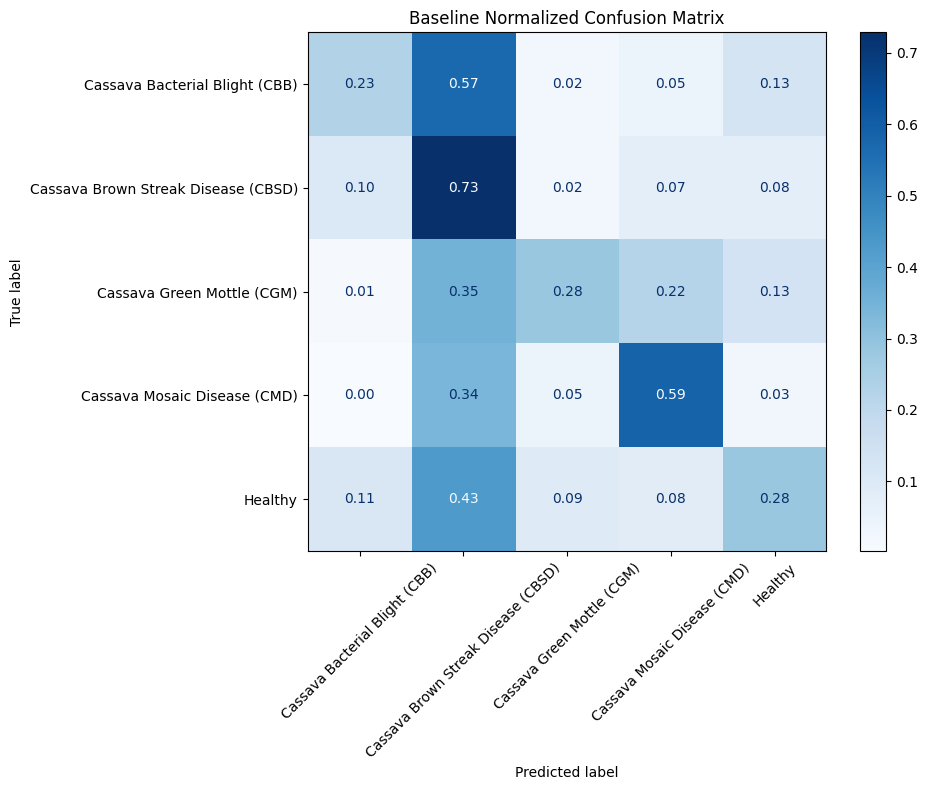

In [93]:
###plot a row_normalized matrix: each row shows where the true class was predicted
cm_normalized = confusion_matrix(
    y_true,
    y_pred,
    labels=class_ids,
    normalize="true"
)

fig, ax = plt.subplots(figsize=(10, 8))
ConfusionMatrixDisplay(
    confusion_matrix=cm_normalized,
    display_labels=class_names
).plot(
    ax=ax,
    cmap="Blues",
    values_format=".2f",
    xticks_rotation=45,
)
plt.title("Baseline Normalized Confusion Matrix")
plt.tight_layout()
plt.show()

In [94]:
##transfer learning and data augmentation
###augment training images only; validation images remain unchanged
augmentation = keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.10),
], name="data_augmentation")

In [95]:
###load the imagenet-pretrained efficientnetBO feature extractor
efficientnet_base = keras.applications.EfficientNetB0(
    include_top=False,
    weights="imagenet",
    input_shape=(224, 224, 3)
)
efficientnet_base.trainable = False

In [96]:
###add new classifier
inputs = keras.Input(shape=(224, 224, 3))
x = augmentation(inputs)
x = efficientnet_base(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(num_classes, activation="softmax")(x)

efficientnet_model = keras.Model(
    inputs,
    outputs,
    name="cassava_efficientnet_b0"
)

efficientnet_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"]
)

efficientnet_model.summary()

Model: "cassava_efficientnet_b0"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_9 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_4      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 5)              │         6,405 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,055,976 (15.47 MB)

 Trainable params: 6,405 (25.02 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [97]:
###training feature extractor
efficientnet_callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=2,
        restore_best_weights=True
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=1,
    ),
]

efficiency_history = efficientnet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=6,
    callbacks=efficientnet_callbacks
)

Epoch 1/6


E0000 00:00:1792211580.905765      49 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/cassava_efficientnet_b0_1/efficientnetb0_1/block2b_drop_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


535/535 ━━━━━━━━━━━━━━━━━━━━ 69s 111ms/step - accuracy: 0.5693 - loss: 1.2261 - val_accuracy: 0.5780 - val_loss: 1.1467 - learning_rate: 0.0010
Epoch 2/6
535/535 ━━━━━━━━━━━━━━━━━━━━ 58s 109ms/step - accuracy: 0.6206 - loss: 1.1037 - val_accuracy: 0.5500 - val_loss: 1.2201 - learning_rate: 0.0010
Epoch 3/6
535/535 ━━━━━━━━━━━━━━━━━━━━ 56s 104ms/step - accuracy: 0.6406 - loss: 1.0579 - val_accuracy: 0.5981 - val_loss: 1.1268 - learning_rate: 5.0000e-04
Epoch 4/6
535/535 ━━━━━━━━━━━━━━━━━━━━ 52s 97ms/step - accuracy: 0.6477 - loss: 1.0449 - val_accuracy: 0.5820 - val_loss: 1.1533 - learning_rate: 5.0000e-04
Epoch 5/6
535/535 ━━━━━━━━━━━━━━━━━━━━ 56s 104ms/step - accuracy: 0.6464 - loss: 1.0381 - val_accuracy: 0.5834 - val_loss: 1.1593 - learning_rate: 2.5000e-04


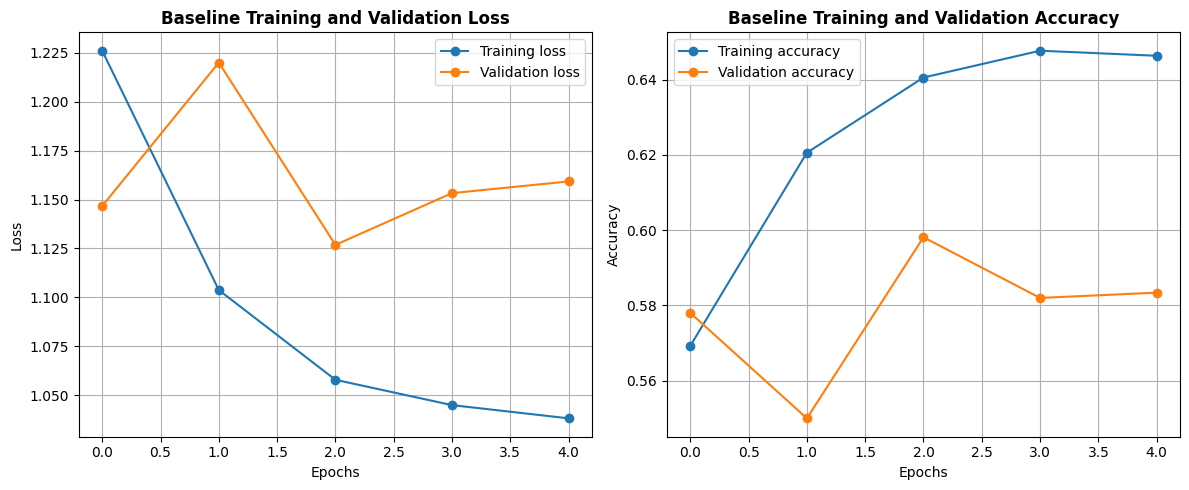

In [98]:
##extract history values
history_dict = efficiency_history.history
loss = history_dict['loss']
val_loss = history_dict['val_loss']
accuracy = history_dict['accuracy']
val_accuracy = history_dict['val_accuracy']
epochs_range = range(len(loss))

##plotting
plt.figure(figsize=(12, 5))

###loss plot
plt.subplot(1, 2, 1)
plt.plot(
    epochs_range,
    loss,
    label="Training loss",
    marker="o"
)
plt.plot(
    epochs_range,
    val_loss,
    label="Validation loss",
    marker="o"
)
plt.title("Baseline Training and Validation Loss",
         fontsize=12,
         fontweight="bold"
)
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

###accuracy plot
plt.subplot(1, 2, 2)
plt.plot(
    epochs_range,
    accuracy,
    label="Training accuracy",
    marker="o"
)
plt.plot(
    epochs_range,
    val_accuracy,
    label="Validation accuracy",
    marker="o"
)
plt.title("Baseline Training and Validation Accuracy",
         fontsize=12,
         fontweight="bold"
)
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [102]:
##show the metrics recorded at each epoch
display(pd.DataFrame(efficiency_history.history))
##predict on the validation set
y_true_batches = []
y_pred_batches = []

for images, labels in val_ds:
    probabilities = efficientnet_model(images, training=False).numpy()
    y_true_batches.append(labels.numpy())
    y_pred_batches.append(np.argmax(probabilities, axis=1))

y_true = np.concatenate(y_true_batches)
y_pred = np.concatenate(y_pred_batches)

class_ids = sorted(label_map)
class_names = [label_map[i] for i in class_ids]

,accuracy,loss,val_accuracy,val_loss,learning_rate
0,0.569259,1.226129,0.578037,1.146691,0.00100
1,0.620611,1.103726,0.550000,1.220072,0.00100
2,0.640591,1.057852,0.598131,1.126833,0.00050
3,0.647719,1.044894,0.582009,1.153307,0.00050
4,0.646375,1.038137,0.583411,1.159279,0.00025


In [103]:
##predict on the validation set
y_true_batches = []
y_pred_batches = []

for images, labels in val_ds:
    probabilities = efficientnet_model(images, training=False).numpy()
    y_true_batches.append(labels.numpy())
    y_pred_batches.append(np.argmax(probabilities, axis=1))

y_true = np.concatenate(y_true_batches)
y_pred = np.concatenate(y_pred_batches)

class_ids = sorted(label_map)
class_names = [label_map[i] for i in class_ids]

In [104]:
##print classification report
print(classification_report(
    y_true,
    y_pred,
    labels=class_ids,
    target_names=class_names,
    digits=3,
    zero_division=0
))

                                     precision    recall  f1-score   support

     Cassava Bacterial Blight (CBB)      0.256     0.673     0.371       217
Cassava Brown Streak Disease (CBSD)      0.453     0.420     0.436       438
         Cassava Green Mottle (CGM)      0.406     0.528     0.459       477
       Cassava Mosaic Disease (CMD)      0.955     0.617     0.750      2632
                            Healthy      0.360     0.684     0.472       516

                           accuracy                          0.598      4280
                          macro avg      0.486     0.585     0.498      4280
                       weighted avg      0.735     0.598     0.633      4280



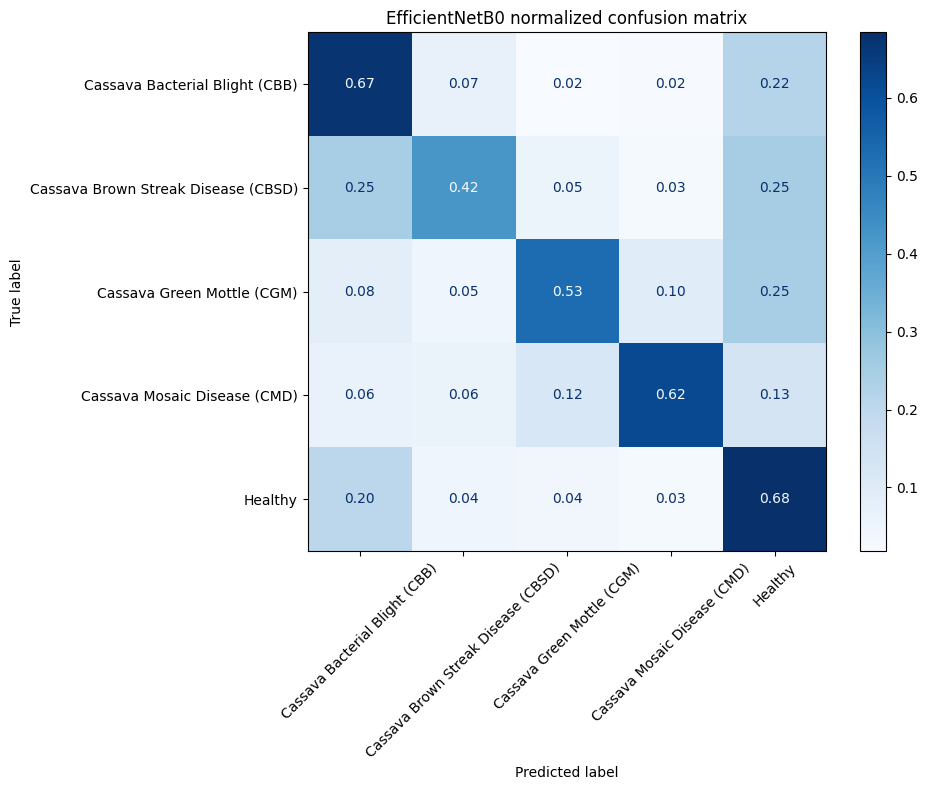

In [105]:
##plot
cm_normalized = confusion_matrix(
    y_true,
    y_pred,
    labels=class_ids,
    normalize="true"
)

fig, ax = plt.subplots(figsize=(10, 8))
ConfusionMatrixDisplay(
    confusion_matrix=cm_normalized,
    display_labels=class_names
).plot(
    ax=ax,
    cmap="Blues",
    values_format=".2f",
    xticks_rotation=45
)
plt.title("EfficientNetB0 normalized confusion matrix")
plt.tight_layout()
plt.show()

In [106]:
##fine-tuning
###unfreeze base model
efficientnet_base.trainable = True

In [107]:
###freeze all layers excetp the las 30 layers of efficientnet to prevent overfitting and catastrophic forgetting of low-level features
for layer in efficientnet_base.layers[:-30]:
    layer.trainable = False

In [108]:
###keep batchnomalization layers frozen
for layers in efficientnet_base.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

print(
    "Trainable efficient layers:",
    sum(layer.trainable for layer in efficientnet_base.layers),
    "of",
    len(efficientnet_base.layers)
)

Trainable efficient layers: 30 of 238


In [109]:
##recompile the model with a much smaller learning rate
efficientnet_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"]
)

fine_tune_callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=2,
        restore_best_weights=True
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=1,
        min_lr=1e-7
    )
]

fine_tune_history = efficientnet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5,
    callbacks=fine_tune_callbacks
)

Epoch 1/5


E0000 00:00:1792212209.317879      49 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/cassava_efficientnet_b0_1/efficientnetb0_1/block2b_drop_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


535/535 ━━━━━━━━━━━━━━━━━━━━ 79s 125ms/step - accuracy: 0.4350 - loss: 1.2899 - val_accuracy: 0.4643 - val_loss: 1.3858 - learning_rate: 1.0000e-05
Epoch 2/5
535/535 ━━━━━━━━━━━━━━━━━━━━ 65s 122ms/step - accuracy: 0.5438 - loss: 1.1736 - val_accuracy: 0.5607 - val_loss: 1.1862 - learning_rate: 1.0000e-05
Epoch 3/5
535/535 ━━━━━━━━━━━━━━━━━━━━ 62s 116ms/step - accuracy: 0.5922 - loss: 1.1183 - val_accuracy: 0.6002 - val_loss: 1.1008 - learning_rate: 1.0000e-05
Epoch 4/5
535/535 ━━━━━━━━━━━━━━━━━━━━ 57s 107ms/step - accuracy: 0.6100 - loss: 1.0849 - val_accuracy: 0.6241 - val_loss: 1.0367 - learning_rate: 1.0000e-05
Epoch 5/5
535/535 ━━━━━━━━━━━━━━━━━━━━ 58s 109ms/step - accuracy: 0.6251 - loss: 1.0513 - val_accuracy: 0.6458 - val_loss: 1.0017 - learning_rate: 1.0000e-05


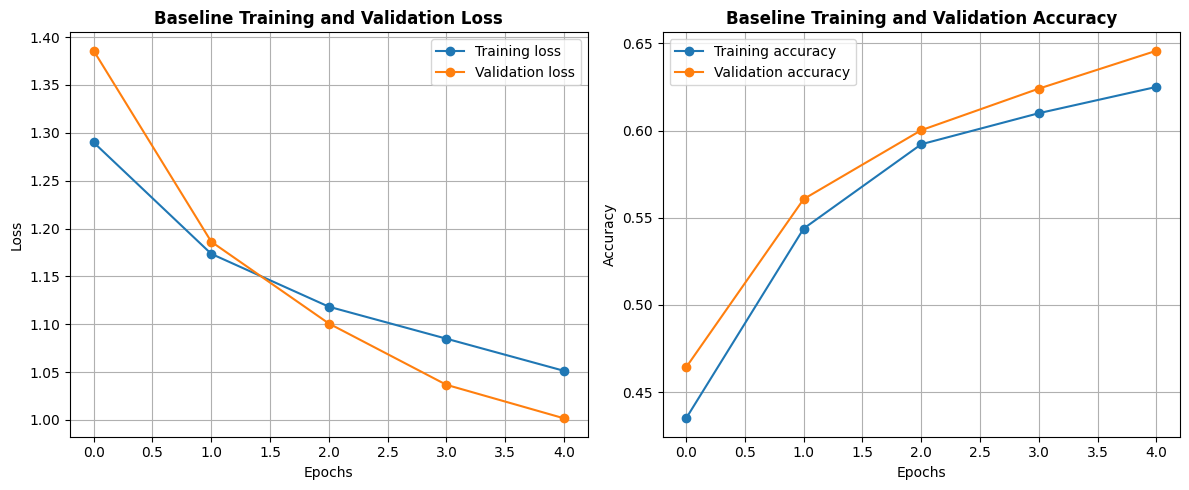

In [110]:
##extract history values
history_dict = fine_tune_history.history
loss = history_dict['loss']
val_loss = history_dict['val_loss']
accuracy = history_dict['accuracy']
val_accuracy = history_dict['val_accuracy']
epochs_range = range(len(loss))

##plotting
plt.figure(figsize=(12, 5))

###loss plot
plt.subplot(1, 2, 1)
plt.plot(
    epochs_range,
    loss,
    label="Training loss",
    marker="o"
)
plt.plot(
    epochs_range,
    val_loss,
    label="Validation loss",
    marker="o"
)
plt.title("Baseline Training and Validation Loss",
         fontsize=12,
         fontweight="bold"
)
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

###accuracy plot
plt.subplot(1, 2, 2)
plt.plot(
    epochs_range,
    accuracy,
    label="Training accuracy",
    marker="o"
)
plt.plot(
    epochs_range,
    val_accuracy,
    label="Validation accuracy",
    marker="o"
)
plt.title("Baseline Training and Validation Accuracy",
         fontsize=12,
         fontweight="bold"
)
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [111]:
y_true_batches = []
y_pred_batches = []

for images, labels in val_ds:
    probabilities = efficientnet_model(images, training=False).numpy()
    y_true_batches.append(labels.numpy())
    y_pred_batches.append(np.argmax(probabilities, axis=1))

y_true = np.concatenate(y_true_batches)
y_pred = np.concatenate(y_pred_batches)

class_ids = sorted(label_map)
class_names = [label_map[i] for i in class_ids]

In [112]:
##classification report
print(classification_report(
    y_true,
    y_pred,
    labels=class_ids,
    target_names=class_names,
    digits=3,
    zero_division=0
))

                                     precision    recall  f1-score   support

     Cassava Bacterial Blight (CBB)      0.297     0.608     0.399       217
Cassava Brown Streak Disease (CBSD)      0.488     0.548     0.516       438
         Cassava Green Mottle (CGM)      0.400     0.593     0.478       477
       Cassava Mosaic Disease (CMD)      0.947     0.670     0.785      2632
                            Healthy      0.446     0.669     0.535       516

                           accuracy                          0.646      4280
                          macro avg      0.516     0.618     0.543      4280
                       weighted avg      0.746     0.646     0.674      4280



,Cassava Bacterial Blight (CBB),Cassava Brown Streak Disease (CBSD),Cassava Green Mottle (CGM),Cassava Mosaic Disease (CMD),Healthy
Cassava Bacterial Blight (CBB),132,24,6,8,47
Cassava Brown Streak Disease (CBSD),83,240,27,17,71
Cassava Green Mottle (CGM),25,32,283,49,88
Cassava Mosaic Disease (CMD),117,166,363,1764,222
Healthy,88,30,28,25,345


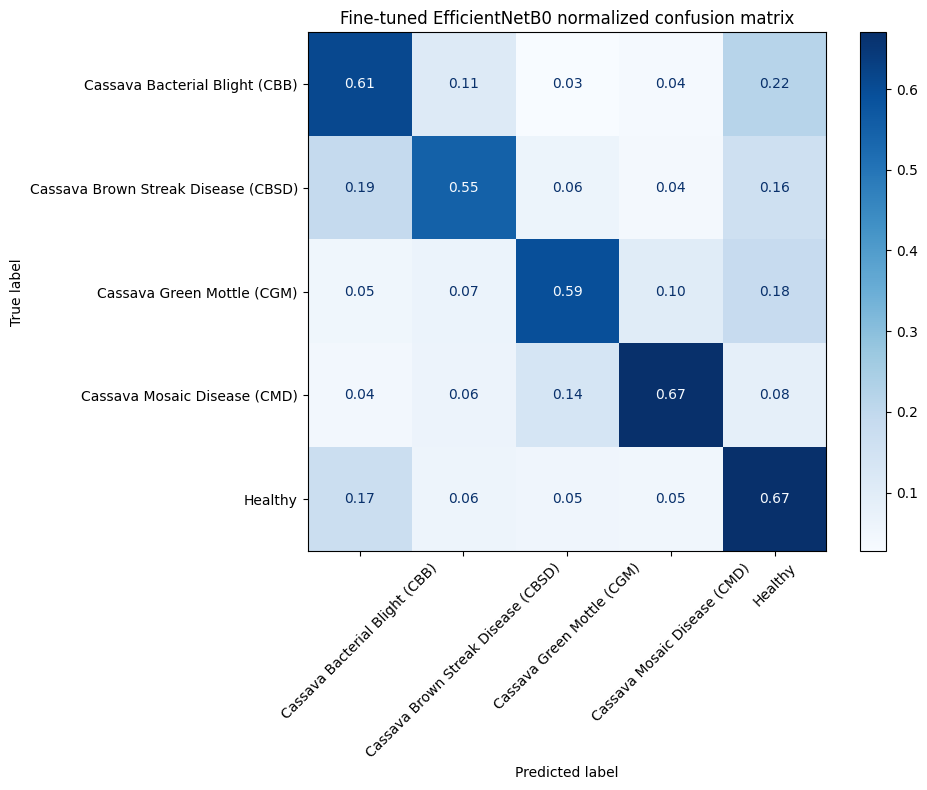

In [113]:
cm_counts = confusion_matrix(y_true, y_pred, labels=class_ids)
display(pd.DataFrame(cm_counts, index=class_names, columns=class_names))

cm_normalized = confusion_matrix(
    y_true,
    y_pred,
    labels=class_ids,
    normalize="true"
)

fig, ax = plt.subplots(figsize=(10, 8))
ConfusionMatrixDisplay(
    confusion_matrix=cm_normalized,
    display_labels=class_names
).plot(
    ax=ax,
    cmap="Blues",
    values_format=".2f",
    xticks_rotation=45
)
plt.title("Fine-tuned EfficientNetB0 normalized confusion matrix")
plt.tight_layout()
plt.show()

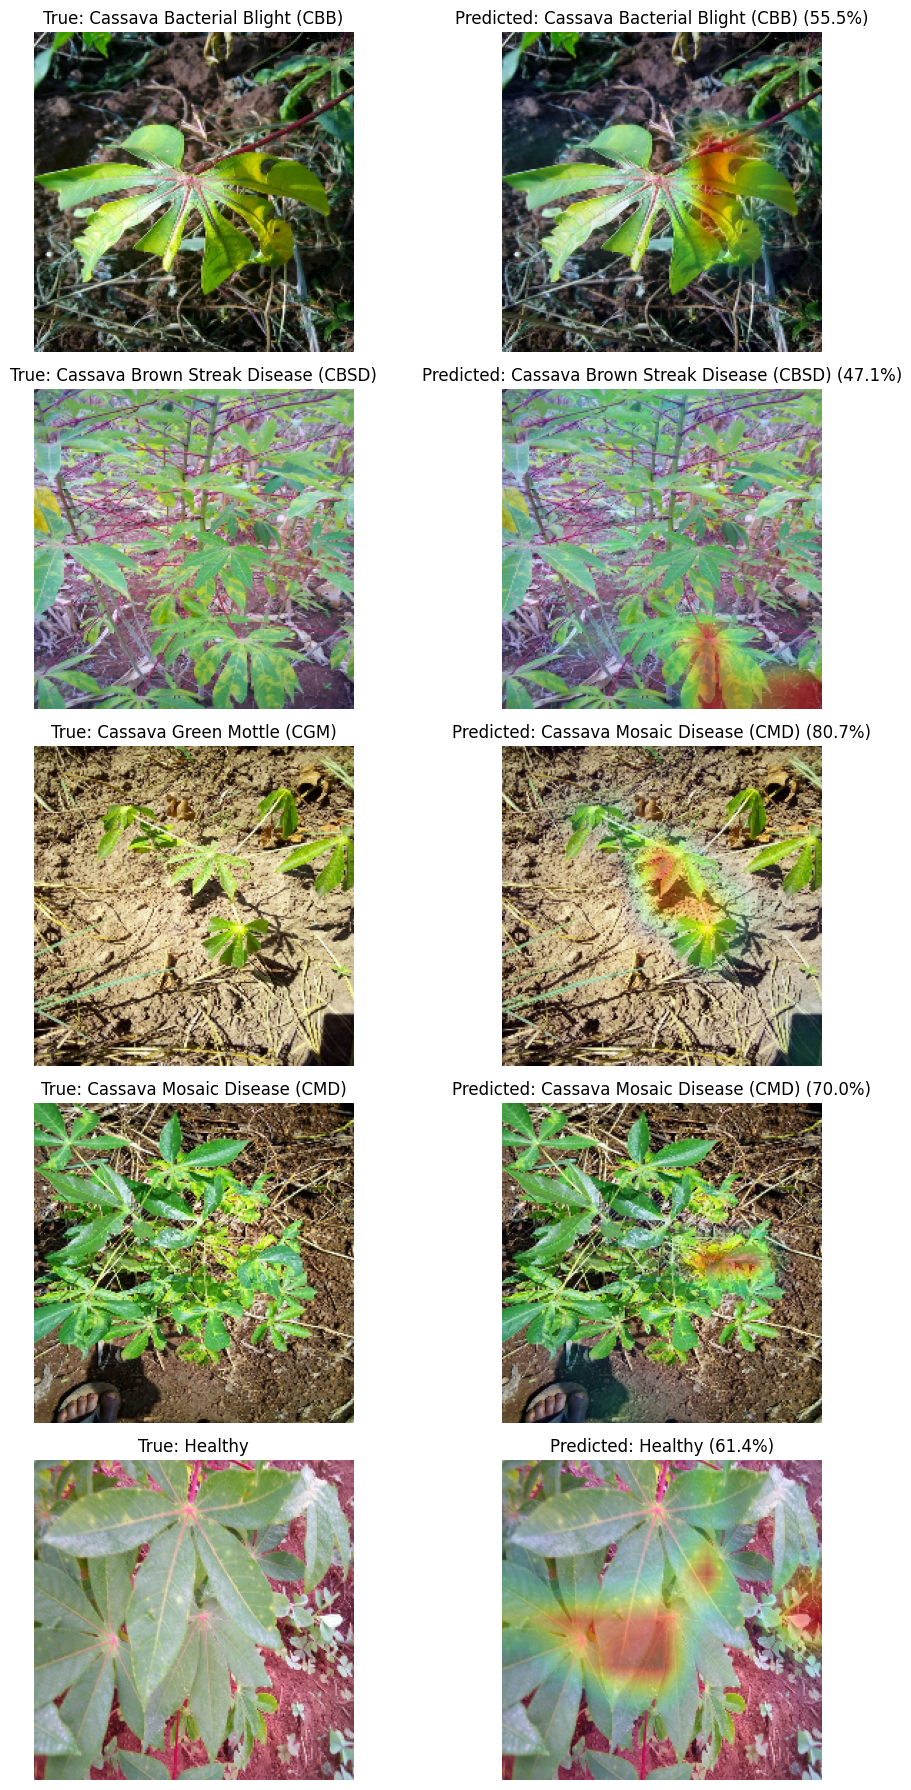

In [114]:
##Model Interpretability (Grad-CAM)
class_ids = sorted(label_map)

###reuse the exact pooling, dropout, and classifier layers from your trained model.
pool_layer = next(
    layer for layer in efficientnet_model.layers
    if isinstance(layer, tf.keras.layers.GlobalAveragePooling2D)
)
dropout_layer = next(
    layer for layer in efficientnet_model.layers
    if isinstance(layer, tf.keras.layers.Dropout)
)
classifier_layer = next(
    layer for layer in efficientnet_model.layers
    if isinstance(layer, tf.keras.layers.Dense)
)

def make_gradcam_heatmap(image):
    image_batch = tf.cast(image[tf.newaxis, ...], tf.float32)

    with tf.GradientTape() as tape:
        x = augmentation(image_batch, training=False)
        feature_maps = efficientnet_base(x, training=False)
        tape.watch(feature_maps)

        x = pool_layer(feature_maps)
        x = dropout_layer(x, training=False)
        predictions = classifier_layer(x)

        predicted_class = tf.argmax(predictions[0], output_type=tf.int32)
        class_score = predictions[:, predicted_class]

    gradients = tape.gradient(class_score, feature_maps)
    if gradients is None:
        raise ValueError("Could not calculate Grad-CAM gradients.")

    channel_weights = tf.reduce_mean(gradients, axis=(1, 2), keepdims=True)
    heatmap = tf.reduce_sum(channel_weights * feature_maps, axis=-1)
    heatmap = tf.maximum(heatmap[0], 0)
    heatmap = tf.math.divide_no_nan(heatmap, tf.reduce_max(heatmap))

    confidence = predictions[0, predicted_class]
    return heatmap, int(predicted_class.numpy()), float(confidence.numpy())

###select one validation image for each true class.
cam_samples = {}

for batch_images, batch_labels in val_ds:
    for image, label in zip(batch_images, batch_labels):
        class_id = int(label.numpy())
        if class_id not in cam_samples:
            cam_samples[class_id] = image

    if len(cam_samples) == len(class_ids):
        break

###show original images beside their Grad-CAM overlays.
fig, axes = plt.subplots(len(class_ids), 2, figsize=(11, 18))

for row, class_id in enumerate(class_ids):
    image = cam_samples[class_id]
    heatmap, predicted_class, confidence = make_gradcam_heatmap(image)

    heatmap = tf.image.resize(
        heatmap[..., tf.newaxis],
        IMG_SIZE,
    ).numpy().squeeze()

    original = np.clip(image.numpy(), 0, 255).astype(np.uint8)
    heatmap_rgb = plt.get_cmap("jet")(heatmap)[..., :3] * 255
    alpha = 0.45 * heatmap[..., np.newaxis]
    overlay = np.clip(
        original * (1 - alpha) + heatmap_rgb * alpha,
        0,
        255,
    ).astype(np.uint8)

    axes[row, 0].imshow(original)
    axes[row, 0].set_title(f"True: {label_map[class_id]}")

    axes[row, 1].imshow(overlay)
    axes[row, 1].set_title(
        f"Predicted: {label_map[predicted_class]} ({confidence:.1%})"
    )

    axes[row, 0].axis("off")
    axes[row, 1].axis("off")

plt.tight_layout()
plt.show()